# Prime-time audience share — exploratory data analysis

Goal: predict `share_15_54` of **channel 3** for 1 Nov 2023 – 13 Jan 2024 (incl. Christmas).
Metric: MAE. This notebook looks for data issues, structure in the identifiers, what drives
the share, and what is (not) available at prediction time.

Sections
1. Load & duplicates
2. Schema and train/test differences
3. Missing values
4. Time coverage
5. Decoding `main_ident`
6. Target: distribution, daily/weekly profile, trend, Christmas
7. `share_15_54_3mo_mean`
8. Naive baselines
9. Numeric features `f_*`
10. Categorical features `f_10`, `f_11`
11. Correlations with the target
12. Competitor channels
13. Takeaways

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

# repo root = first parent that contains data/train.csv (works from notebooks/ or repo root)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "train.csv").exists())
DATA = ROOT / "data"

TARGET, MO3 = "share_15_54", "share_15_54_3mo_mean"
KEY = ["main_ident", "timeslot_datetime_from", "channel_id"]
CHANNELS, SCORED = [3, 4, 9, 54], 3
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

# palette: fixed categorical order (channel -> colour never changes), one-hue sequential, blue/red diverging
CH_COLOR = {3: "#257de0", 4: "#f47230", 9: "#00b894", 54: "#f2a600"}
GRAY, TEXT2 = "#9c9c9c", "#666666"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cce3fd", "#84b9f3", "#338ced", "#2370cd", "#0f4a96", "#0e3d7e"])
DIV = LinearSegmentedColormap.from_list("div", ["#1757ac", "#84b9f3", "#efefef", "#f29a9a", "#c0302f"])

mpl.rcParams.update({
    "figure.figsize": (11, 4), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRAY, "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "axes.titleweight": "bold", "axes.titlesize": 12, "legend.frameon": False,
})


def fcols(df, ch=None, i=None):
    """Columns ch{C}__f_{i}, optionally filtered by channel and/or feature index."""
    out = []
    for c in df.columns:
        if "__f_" in c:
            c_ch, c_i = c[2:].split("__f_")
            if (ch is None or int(c_ch) == ch) and (i is None or int(c_i) == i):
                out.append(c)
    return out

## 1. Load & duplicates

train (31356, 53)  test (1751, 53)
full-row duplicates in train: 15199 (48%)
key duplicates in train:      15199
keys with conflicting target: 0
duplicates in test:           0
train/test key overlap:       0
duplicate copies adjacent in file: 1.0
timeslots where every channel has the same copy count: 1.0


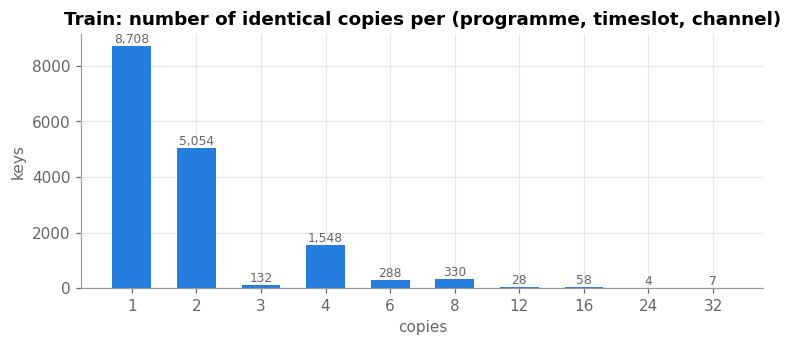

In [2]:
train_raw = pd.read_csv(DATA / "train.csv")
test_raw = pd.read_csv(DATA / "test.csv")
print("train", train_raw.shape, " test", test_raw.shape)

copies = train_raw.groupby(KEY).size()
print("full-row duplicates in train:", train_raw.duplicated().sum(), f"({train_raw.duplicated().mean():.0%})")
print("key duplicates in train:     ", train_raw.duplicated(subset=KEY).sum())
print("keys with conflicting target:", (train_raw.groupby(KEY)[TARGET].nunique() > 1).sum())
print("duplicates in test:          ", test_raw.drop(columns="row_id").duplicated().sum())
print("train/test key overlap:      ", len(train_raw[KEY].drop_duplicates().merge(test_raw[KEY])))

pos = train_raw.reset_index().groupby(KEY)["index"].agg(["min", "max", "size"]).query("size > 1")
print("duplicate copies adjacent in file:", ((pos["max"] - pos["min"] + 1) == pos["size"]).mean())
same = copies.rename("n").reset_index().groupby("timeslot_datetime_from")["n"].nunique().eq(1).mean()
print("timeslots where every channel has the same copy count:", same)

vc = copies.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(8, 3))
ax.bar(vc.index.astype(str), vc.values, color=CH_COLOR[3], width=0.6)
ax.set(title="Train: number of identical copies per (programme, timeslot, channel)", xlabel="copies", ylabel="keys")
for x, v in zip(vc.index.astype(str), vc.values):
    ax.annotate(f"{v:,}", (x, v), ha="center", va="bottom", fontsize=8, color=TEXT2)
plt.show()

**~48% of train rows are exact duplicates.** Copy counts are products of 2 and 3, the copies are
adjacent and every channel in a timeslot is multiplied equally — a classic join fan-out on a
non-unique timeslot-level table. The target never conflicts, so `drop_duplicates()` is safe. Not
removing them would over-weight some slots and leak copies across random CV folds.

In [3]:
def add_derived(df):
    df = df.copy()
    df["t"] = pd.to_datetime(df["timeslot_datetime_from"])
    df["date"] = df["t"].dt.normalize()
    df["hour"] = df["t"].dt.hour
    df["dow"] = df["t"].dt.dayofweek
    df["minute_of_evening"] = (df["hour"] - 16) * 60 + df["t"].dt.minute
    ident, ch = df["main_ident"].astype(str), df["channel_id"].astype(str)
    df["ident_prefix_ok"] = [a.startswith(b) for a, b in zip(ident, ch)]
    rest = pd.Series([a[len(b):] for a, b in zip(ident, ch)], index=df.index)
    df["prog_start"] = pd.to_datetime(rest.str[:12], format="%y%m%d%H%M%S", errors="coerce")
    df["ident_suffix"] = rest.str[12:]
    df["elapsed_min"] = (df["t"] - df["prog_start"]).dt.total_seconds() / 60
    return df

train = add_derived(train_raw.drop_duplicates().reset_index(drop=True))
test = add_derived(test_raw)
c3 = train[train["channel_id"] == SCORED].copy()
t3 = test[test["channel_id"] == SCORED].copy()
print("train after dedup:", train.shape, " ch3 rows:", len(c3), " test ch3 rows:", len(t3))

train after dedup: (16157, 62)  ch3 rows: 4002  test ch3 rows: 435


## 2. Schema and train/test differences

In [4]:
print("only in train:", sorted(set(train_raw.columns) - set(test_raw.columns)))
print("only in test: ", sorted(set(test_raw.columns) - set(train_raw.columns)))
mism = {c: (str(train_raw[c].dtype), str(test_raw[c].dtype))
        for c in train_raw.columns.intersection(test_raw.columns) if train_raw[c].dtype != test_raw[c].dtype}
print("dtype mismatches (train, test):", mism)
pd.DataFrame({"train rows": train["channel_id"].value_counts(), "test rows": test["channel_id"].value_counts()}).sort_index()

only in train: ['share_15_54']
only in test:  ['row_id']
dtype mismatches (train, test): {'ch3__f_10': ('object', 'float64'), 'ch3__f_11': ('object', 'float64'), 'ch54__f_10': ('object', 'float64'), 'ch54__f_11': ('object', 'float64'), 'ch4__f_10': ('object', 'float64'), 'ch4__f_11': ('object', 'float64')}


,train rows,test rows
channel_id,,
3,4002,435
4,3384,372
9,4236,445
54,4535,499


`f_10` / `f_11` are strings in train but float in test — because they are **entirely empty in test**
(next section). Any pipeline that encodes them must not crash on an all-NaN float column.

## 3. Missing values

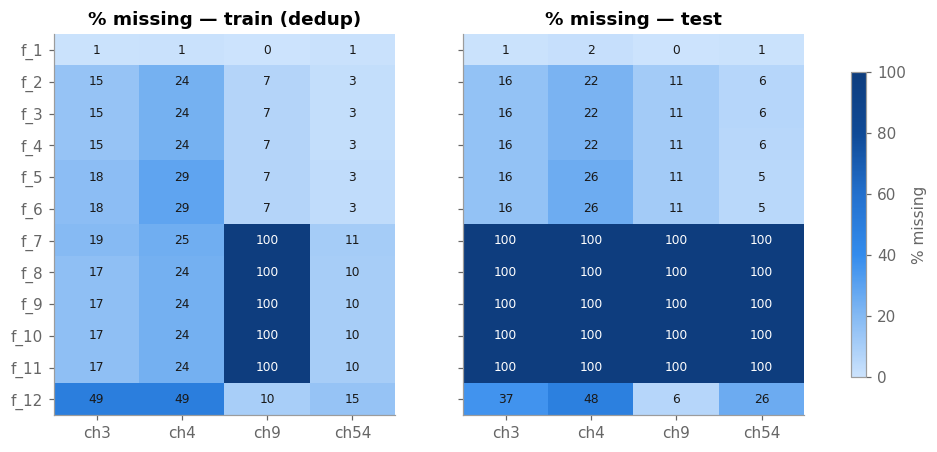

present in train but 100% missing in test: ['ch3__f_7', 'ch3__f_8', 'ch3__f_9', 'ch3__f_10', 'ch3__f_11', 'ch54__f_7', 'ch54__f_8', 'ch54__f_9', 'ch54__f_10', 'ch54__f_11', 'ch4__f_7', 'ch4__f_8', 'ch4__f_9', 'ch4__f_10', 'ch4__f_11']


In [5]:
def miss_table(df):
    return pd.DataFrame({f"ch{ch}": [df[f"ch{ch}__f_{i}"].isna().mean() * 100 for i in range(1, 13)]
                         for ch in CHANNELS}, index=[f"f_{i}" for i in range(1, 13)])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, (name, df) in zip(axes, [("train (dedup)", train), ("test", test)]):
    m = miss_table(df)
    im = ax.imshow(m.values, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
    ax.set(xticks=range(4), xticklabels=m.columns, yticks=range(12), yticklabels=m.index, title=f"% missing — {name}")
    ax.grid(False)
    for (r, c), v in np.ndenumerate(m.values):
        ax.text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else "#191919")
fig.colorbar(im, ax=axes, shrink=0.8, label="% missing")
plt.show()

useless = [c for c in fcols(test) if test[c].isna().all() and train[c].notna().any()]
print("present in train but 100% missing in test:", useless)

**`f_7` … `f_11` are 100% missing in test for every channel** (and always missing for ch9).
A model trained on them will see only NaN at predict time — drop them or use them only for
building features that are available in test.

In [6]:
rows = []
for col in [f"ch3__f_{i}" for i in (2, 5, 12)] + [f"ch4__f_{i}" for i in (2, 12)]:
    g = c3.groupby(c3[col].isna())[TARGET].agg(["mean", "size"])
    rows.append({"column": col, "share if present": g.loc[False, "mean"], "share if missing": g.loc[True, "mean"],
                 "n missing": g.loc[True, "size"]})
pd.DataFrame(rows).set_index("column").round(2)

,share if present,share if missing,n missing
column,,,
ch3__f_2,23.03,17.63,125
ch3__f_5,23.01,20.66,242
ch3__f_12,19.40,26.75,1886
ch4__f_2,22.24,24.22,1266
ch4__f_12,19.45,26.20,2027


Missingness carries signal (e.g. ch3 share ~27% when `ch3__f_12` is missing vs ~19%) → keep missing indicators.

## 4. Time coverage

train: 2022-01-01 17:10:00 → 2023-10-31 22:15:00 | missing days: [datetime.date(2023, 5, 31)]
   timeslots by #channels present: {1: 69, 2: 508, 3: 1620, 4: 2553}
test: 2023-11-01 16:10:00 → 2024-01-13 23:45:00 | missing days: []
   timeslots by #channels present: {1: 15, 2: 96, 3: 160, 4: 266}


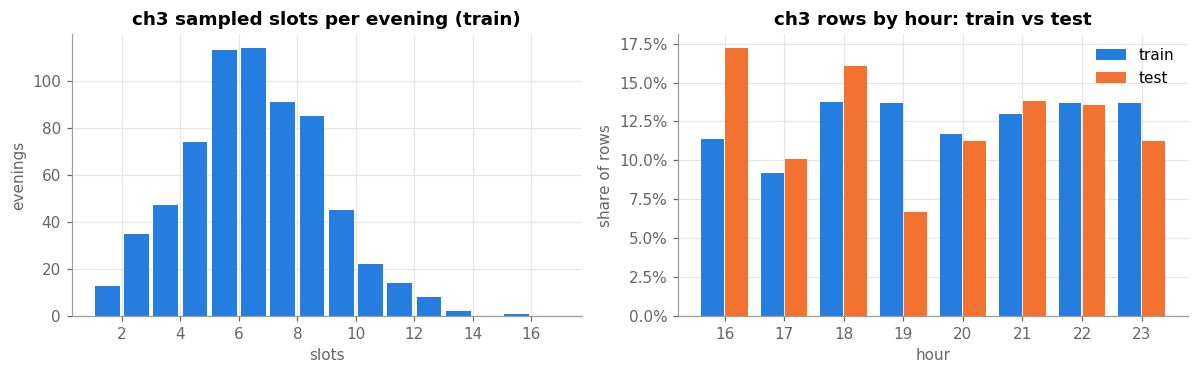

In [7]:
for name, df in [("train", train), ("test", test)]:
    days = pd.date_range(df["date"].min(), df["date"].max())
    print(f"{name}: {df['t'].min()} → {df['t'].max()} | missing days: {[d.date() for d in sorted(set(days) - set(df['date']))]}")
    print("   timeslots by #channels present:", df.groupby("timeslot_datetime_from").size().value_counts().sort_index().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
spd = c3.groupby("date").size()
axes[0].hist(spd, bins=range(1, 18), color=CH_COLOR[3], rwidth=0.85)
axes[0].set(title="ch3 sampled slots per evening (train)", xlabel="slots", ylabel="evenings")
w = pd.DataFrame({"train": c3["hour"].value_counts(normalize=True), "test": t3["hour"].value_counts(normalize=True)}).sort_index()
x = np.arange(len(w))
axes[1].bar(x - 0.2, w["train"], 0.38, label="train", color=CH_COLOR[3])
axes[1].bar(x + 0.2, w["test"], 0.38, label="test", color=CH_COLOR[4])
axes[1].set(xticks=x, xticklabels=w.index, title="ch3 rows by hour: train vs test", xlabel="hour", ylabel="share of rows")
axes[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
axes[1].legend()
plt.tight_layout(); plt.show()

Timeslots are a **sparse sample** (~6 per evening per channel out of 96 possible 5-min slots), not a
full grid; one day (2023-05-31) is missing. Not every channel is present in every timeslot.
The **test hour mix differs** (few 19h rows, more 16h) — the overall test MAE will weight hours differently
than a random train split does.

## 5. Decoding `main_ident`

Hypothesis: `<channel_id><YYMMDDHHMMSS = programme start><4-digit suffix>`.

In [8]:
for name, df in [("train", train), ("test", test)]:
    print(f"{name}: prefix==channel {df['ident_prefix_ok'].mean():.0%}, unparsable starts {df['prog_start'].isna().sum()}, "
          f"suffixes {df['ident_suffix'].value_counts().to_dict()}, elapsed min range "
          f"[{df['elapsed_min'].min():.1f}, {df['elapsed_min'].max():.1f}]")
print("test ch3 programmes seen in train:", t3["main_ident"].isin(train["main_ident"]).mean())
per_prog = c3.groupby("main_ident")[TARGET].agg(["size", "std"])
print(f"ch3 rows per programme {per_prog['size'].mean():.2f}; within-programme std {per_prog['std'].mean():.2f} "
      f"vs overall {c3[TARGET].std():.2f}")

train: prefix==channel 100%, unparsable starts 0, suffixes {'0000': 7747, '0020': 7327, '0010': 617, '0030': 466}, elapsed min range [-5.0, 225.2]
test: prefix==channel 100%, unparsable starts 0, suffixes {'0000': 856, '0020': 792, '0030': 78, '0010': 25}, elapsed min range [-5.0, 208.2]
test ch3 programmes seen in train: 0.0


ch3 rows per programme 1.60; within-programme std 2.74 vs overall 7.76


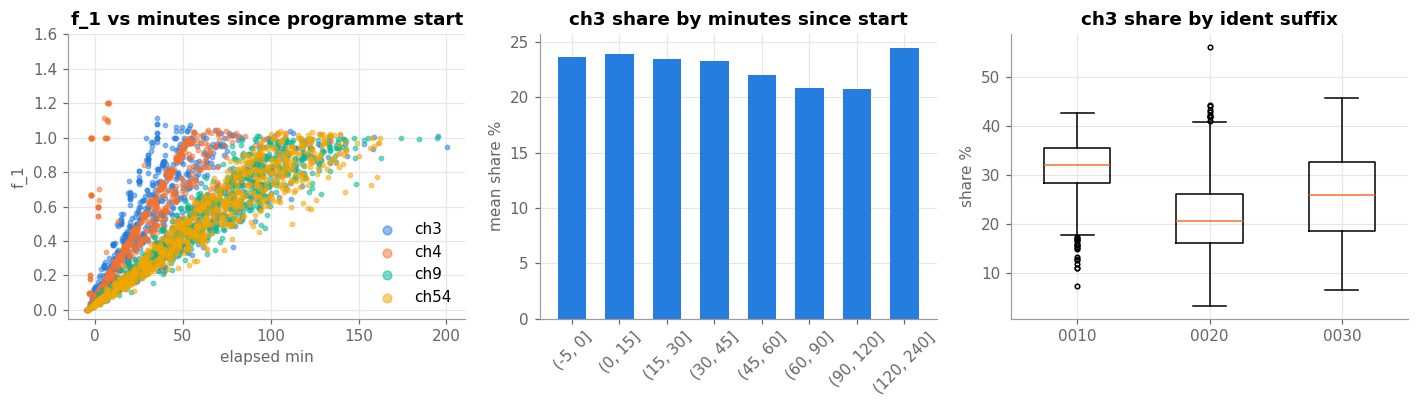

              share     n typical_start
ident_suffix                           
0010          30.96   412         19:30
0020          21.40  3124         20:21
0030          25.51   466         18:29


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ch in CHANNELS:
    d = train[train["channel_id"] == ch].sample(800, random_state=0)
    axes[0].scatter(d["elapsed_min"], d[f"ch{ch}__f_1"], s=8, alpha=0.5, color=CH_COLOR[ch], label=f"ch{ch}")
axes[0].set(title="f_1 vs minutes since programme start", xlabel="elapsed min", ylabel="f_1", ylim=(-0.05, 1.6))
axes[0].legend(markerscale=2)

bins = [-5, 0, 15, 30, 45, 60, 90, 120, 240]
g = c3.groupby(pd.cut(c3["elapsed_min"], bins), observed=True)[TARGET].agg(["mean", "size"])
axes[1].bar(range(len(g)), g["mean"], color=CH_COLOR[3], width=0.6)
axes[1].set(xticks=range(len(g)), xticklabels=[str(i) for i in g.index], title="ch3 share by minutes since start",
            ylabel="mean share %")
axes[1].tick_params(axis="x", rotation=45)

s = c3.groupby("ident_suffix")[TARGET]
axes[2].boxplot([v.values for _, v in s], tick_labels=list(s.groups), widths=0.5,
                medianprops={"color": CH_COLOR[4]}, flierprops={"markersize": 3})
axes[2].set(title="ch3 share by ident suffix", ylabel="share %")
plt.tight_layout(); plt.show()

print(c3.groupby("ident_suffix").agg(share=(TARGET, "mean"), n=(TARGET, "size"),
      typical_start=("prog_start", lambda s: s.dt.strftime("%H:%M").mode().iloc[0])).round(2))

- The ident decodes cleanly: channel prefix always matches, start parses for every row, elapsed
  time is in [-5, 225] min (negative = programme starts inside the 5-min slot).
- **`f_1` ≈ programme progress** (elapsed / duration); values > 1 = overrun.
- **No ch3 programme in test appears in train** (the ident contains the air date) → target encoding on
  `main_ident` is useless; programme *start time*, *elapsed minutes* and *suffix* are usable.
- Suffix `0010` = slots starting exactly 19:30 (news-type block) with a much higher share.

## 6. Target

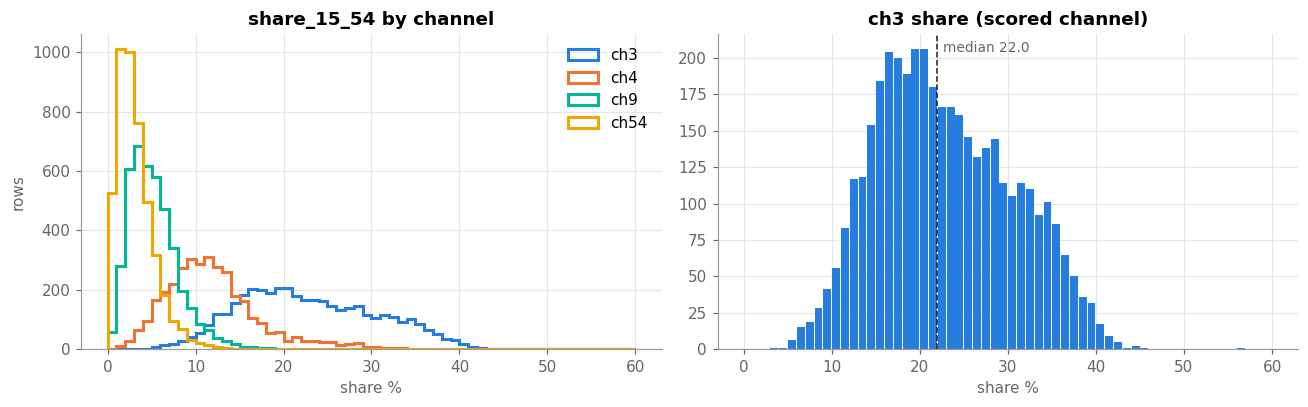

,count,mean,std,min,25%,50%,75%,max
channel_id,,,,,,,,
3,4002.0,22.87,7.76,3.37,16.89,21.95,28.66,56.08
4,3384.0,11.82,5.23,1.08,8.25,11.18,14.23,35.85
9,4236.0,5.23,2.81,0.21,3.14,4.76,6.69,22.39
54,4535.0,3.13,2.09,0.00,1.60,2.68,4.17,15.49


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
bins = np.linspace(0, 60, 61)
for ch in CHANNELS:
    axes[0].hist(train.loc[train["channel_id"] == ch, TARGET], bins=bins, histtype="step", linewidth=2,
                 color=CH_COLOR[ch], label=f"ch{ch}")
axes[0].set(title="share_15_54 by channel", xlabel="share %", ylabel="rows"); axes[0].legend()
axes[1].hist(c3[TARGET], bins=bins, color=CH_COLOR[3], rwidth=0.9)
axes[1].axvline(c3[TARGET].median(), color="#191919", linewidth=1, linestyle="--")
axes[1].annotate(f"median {c3[TARGET].median():.1f}", (c3[TARGET].median(), 1), xycoords=("data", "axes fraction"),
                 xytext=(4, -12), textcoords="offset points", fontsize=9, color=TEXT2)
axes[1].set(title="ch3 share (scored channel)", xlabel="share %")
plt.tight_layout(); plt.show()
train.groupby("channel_id")[TARGET].describe().round(2)

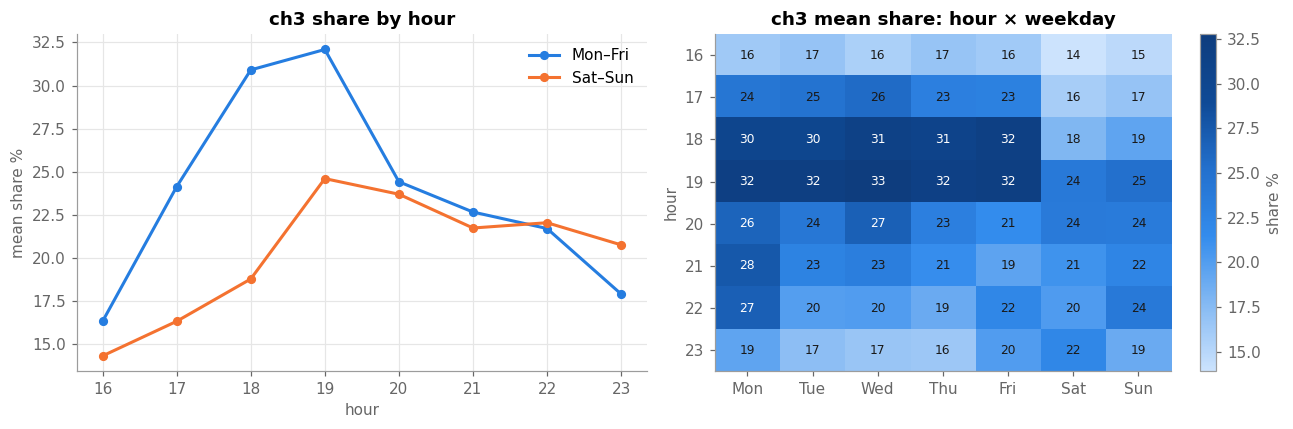

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
prof = c3.assign(weekend=c3["dow"] >= 5).groupby(["weekend", "hour"])[TARGET].mean().unstack(0)
axes[0].plot(prof.index, prof[False], marker="o", markersize=5, color=CH_COLOR[3], label="Mon–Fri")
axes[0].plot(prof.index, prof[True], marker="o", markersize=5, color=CH_COLOR[4], label="Sat–Sun")
axes[0].set(title="ch3 share by hour", xlabel="hour", ylabel="mean share %"); axes[0].legend()

hm = c3.pivot_table(index="hour", columns="dow", values=TARGET, aggfunc="mean")
im = axes[1].imshow(hm.values, cmap=SEQ, aspect="auto")
axes[1].set(xticks=range(7), xticklabels=DOW, yticks=range(len(hm)), yticklabels=hm.index,
            title="ch3 mean share: hour × weekday", ylabel="hour")
axes[1].grid(False)
for (r, c), v in np.ndenumerate(hm.values):
    axes[1].text(c, r, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 26 else "#191919")
fig.colorbar(im, ax=axes[1], label="share %")
plt.tight_layout(); plt.show()

Time is the dominant driver: weekday share peaks ~31–32% at 18–19h; weekend early evening is ~10 points
lower (different schedule). Late evening on Mondays is notably higher than other weekdays.

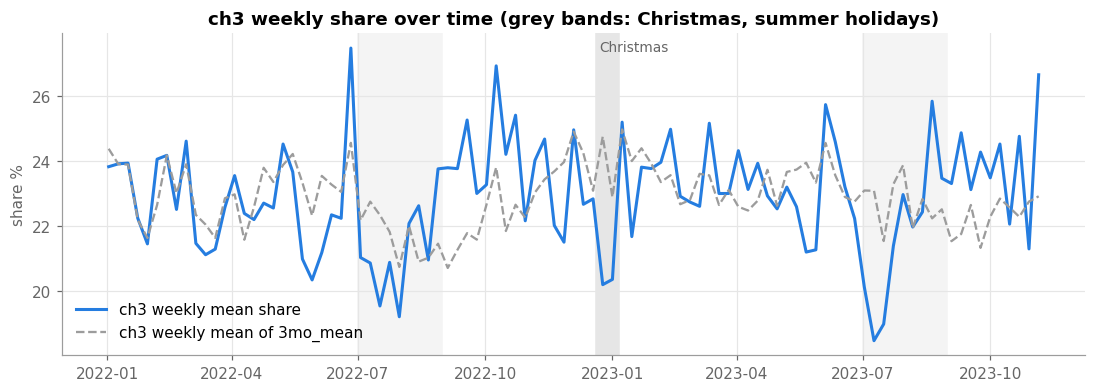

monthly mean range: 2023-07 20.19 → 2022-10 24.58


In [12]:
fig, ax = plt.subplots(figsize=(12, 3.8))
wk = c3.set_index("t")[[TARGET, MO3]].resample("W").mean()
ax.plot(wk.index, wk[TARGET], color=CH_COLOR[3], label="ch3 weekly mean share")
ax.plot(wk.index, wk[MO3], color=GRAY, linewidth=1.5, linestyle="--", label="ch3 weekly mean of 3mo_mean")
for start, end in [("2022-12-20", "2023-01-06")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#e6e6e6", zorder=0)
    ax.annotate("Christmas", (pd.Timestamp(start), 1), xycoords=("data", "axes fraction"), xytext=(2, -12),
                textcoords="offset points", fontsize=9, color=TEXT2)
for start, end in [("2022-07-01", "2022-08-31"), ("2023-07-01", "2023-08-31")]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(end), color="#f4f4f4", zorder=0)
ax.set(title="ch3 weekly share over time (grey bands: Christmas, summer holidays)", ylabel="share %")
ax.legend(loc="lower left")
plt.show()

m = c3.groupby(c3["t"].dt.to_period("M"))[TARGET].mean()
print("monthly mean range:", m.idxmin(), round(m.min(), 2), "→", m.idxmax(), round(m.max(), 2))

No strong long-term trend; dips in July (summer) both years; weekly noise ±2 points.

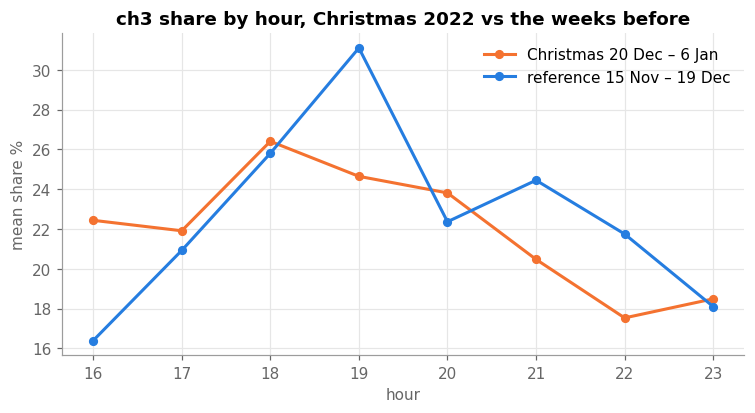

n Christmas rows: 112, overall mean 21.96 vs 22.75


In [13]:
xmas = c3[(c3["t"] >= "2022-12-20") & (c3["t"] < "2023-01-07")]
ref = c3[(c3["t"] >= "2022-11-15") & (c3["t"] < "2022-12-20")]
p = pd.DataFrame({"Christmas 20 Dec – 6 Jan": xmas.groupby("hour")[TARGET].mean(),
                  "reference 15 Nov – 19 Dec": ref.groupby("hour")[TARGET].mean()})
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(p.index, p.iloc[:, 0], marker="o", markersize=5, color=CH_COLOR[4], label=p.columns[0])
ax.plot(p.index, p.iloc[:, 1], marker="o", markersize=5, color=CH_COLOR[3], label=p.columns[1])
ax.set(title="ch3 share by hour, Christmas 2022 vs the weeks before", xlabel="hour", ylabel="mean share %")
ax.legend(); plt.show()
print(f"n Christmas rows: {len(xmas)}, overall mean {xmas[TARGET].mean():.2f} vs {ref[TARGET].mean():.2f}")

Christmas reshapes the evening rather than shifting the level: 16h jumps ~6 points (holiday films for
families), the 19h peak and 22h drop. Only **one** Christmas in train (~110 ch3 rows) → a holiday flag
that interacts with hour is worth trying but will be noisy.

In [14]:
cols = ["timeslot_datetime_from", "hour", "dow", "elapsed_min", TARGET, MO3, "ch3__f_10", "ch3__f_11"]
print("Most extreme ch3 slots relative to the 3-month level:")
ratio = c3[TARGET] / c3[MO3]
pd.concat([c3.loc[ratio.nlargest(5).index, cols], c3.loc[ratio.nsmallest(5).index, cols]]).round(2)

Most extreme ch3 slots relative to the 3-month level:


,timeslot_datetime_from,hour,dow,elapsed_min,share_15_54,share_15_54_3mo_mean,ch3__f_10,ch3__f_11
11727,2023-04-15T23:15:00.000000,23,5,66.98,56.08,20.39,Komedie,Česko
15501,2023-09-18T22:45:00.000000,22,0,61.48,42.25,18.95,NaN,NaN
5949,2022-08-27T23:10:00.000000,23,5,169.78,40.48,18.27,Akční,USA
11731,2023-04-15T23:30:00.000000,23,5,81.98,44.05,20.01,Komedie,Česko
14894,2023-08-26T23:10:00.000000,23,5,167.42,39.63,18.13,Akční,USA
1054,2022-02-12T16:20:00.000000,16,5,33.28,3.37,16.76,Komedie,USA
5655,2022-08-16T23:55:00.000000,23,1,12.93,4.17,18.13,Drama,USA
3570,2022-05-23T17:30:00.000000,17,0,-2.37,6.18,23.12,Soutěžní,Česko
13744,2023-07-09T18:00:00.000000,18,6,39.53,6.61,24.74,Komedie,Česko
13708,2023-07-07T22:35:00.000000,22,4,0.82,5.88,21.66,Akční,USA


## 7. `share_15_54_3mo_mean`

corr(3mo_mean, rolling mean of ch3 target at same hour): {'past 90d': 0.871, 'centred 90d': 0.851, 'future 90d': 0.83, 'past 90d, lag 30d': 0.876}
corr(3mo_mean, target) per channel: {3: 0.609, 4: 0.359, 9: 0.356, 54: 0.323}


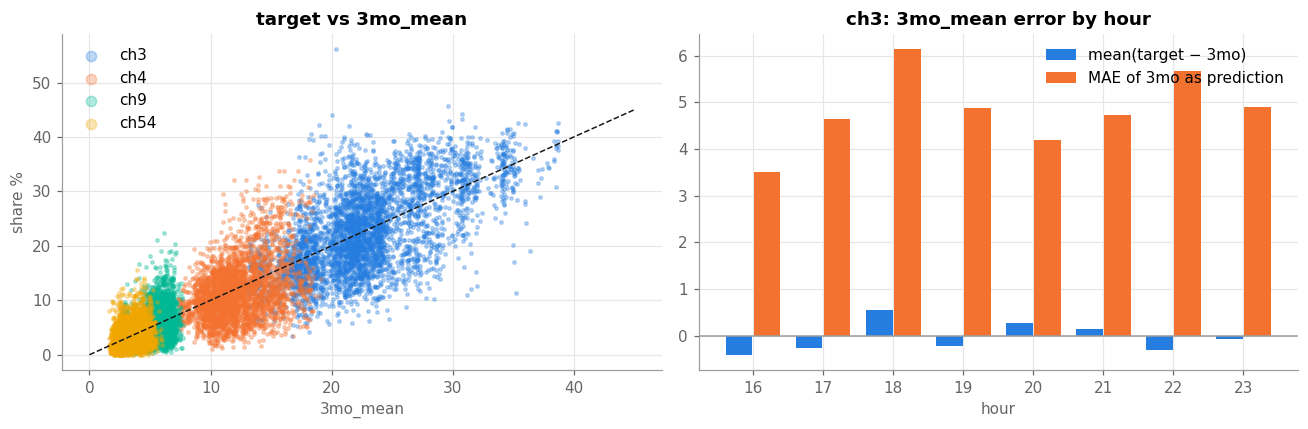

test ch3 3mo_mean mean: 21.39  train: 22.89


In [15]:
c3s = c3.sort_values("t")
res = {}
for name, (lo, hi) in {"past 90d": (-90, 0), "centred 90d": (-45, 45), "future 90d": (0, 90),
                       "past 90d, lag 30d": (-120, -30)}.items():
    est = pd.Series(np.nan, index=c3s.index)
    for _, g in c3s.groupby("hour"):
        tv, yv = g["t"].to_numpy(), g[TARGET].to_numpy()
        for idx, t in zip(g.index, tv):
            msk = (tv >= t + np.timedelta64(lo, "D")) & (tv < t + np.timedelta64(hi, "D")) & (tv != t)
            if msk.any():
                est[idx] = yv[msk].mean()
    res[name] = round(float(c3s[MO3].corr(est)), 3)
print("corr(3mo_mean, rolling mean of ch3 target at same hour):", res)
print("corr(3mo_mean, target) per channel:",
      {ch: round(float(d[TARGET].corr(d[MO3])), 3) for ch, d in train.groupby("channel_id")})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ch in CHANNELS:
    d = train[train["channel_id"] == ch]
    axes[0].scatter(d[MO3], d[TARGET], s=5, alpha=0.3, color=CH_COLOR[ch], label=f"ch{ch}")
axes[0].plot([0, 45], [0, 45], color="#191919", linewidth=1, linestyle="--")
axes[0].set(title="target vs 3mo_mean", xlabel="3mo_mean", ylabel="share %"); axes[0].legend(markerscale=3)
r = (c3[TARGET] - c3[MO3]).groupby(c3["hour"]).agg(["mean", lambda s: s.abs().mean()])
r.columns = ["bias", "MAE"]
x = np.arange(len(r))
axes[1].bar(x - 0.2, r["bias"], 0.38, color=CH_COLOR[3], label="mean(target − 3mo)")
axes[1].bar(x + 0.2, r["MAE"], 0.38, color=CH_COLOR[4], label="MAE of 3mo as prediction")
axes[1].axhline(0, color=GRAY, linewidth=1)
axes[1].set(xticks=x, xticklabels=r.index, title="ch3: 3mo_mean error by hour", xlabel="hour"); axes[1].legend()
plt.tight_layout(); plt.show()
print("test ch3 3mo_mean mean:", round(t3[MO3].mean(), 2), " train:", round(c3[MO3].mean(), 2))

The 3-month mean is a smoothed, roughly **trailing** time-of-day level (best match with a ~1-month lag),
not a leak. It tracks the level well (corr 0.61 for ch3) but misses slot-to-slot variation. In test the
ch3 level is lower (21.4 vs 22.9 on average in train) — partly the different hour mix.

## 8. Naive baselines (time split: last 2 months of train as validation)

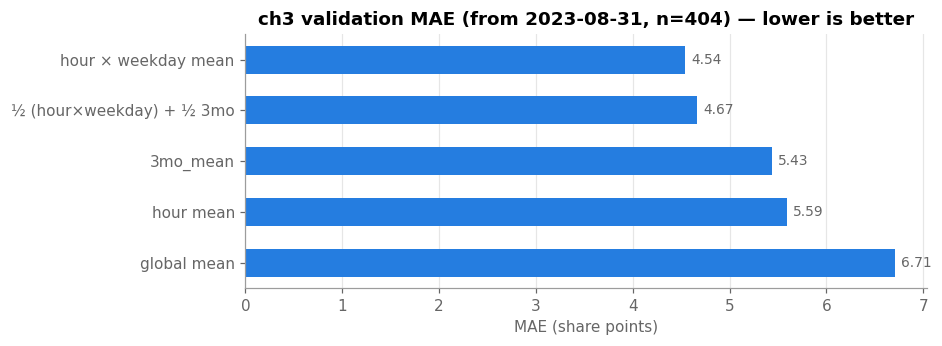

In [16]:
cut = c3["t"].max() - pd.DateOffset(months=2)
fit, val = c3[c3["t"] < cut], c3[c3["t"] >= cut]
hd = fit.groupby(["hour", "dow"])[TARGET].mean()
preds = {
    "global mean": np.full(len(val), fit[TARGET].mean()),
    "hour mean": val["hour"].map(fit.groupby("hour")[TARGET].mean()),
    "3mo_mean": val[MO3],
    "hour × weekday mean": pd.Series(list(zip(val["hour"], val["dow"])), index=val.index).map(hd),
    "½ (hour×weekday) + ½ 3mo": 0.5 * pd.Series(list(zip(val["hour"], val["dow"])), index=val.index).map(hd) + 0.5 * val[MO3],
}
maes = pd.Series({k: float(np.mean(np.abs(val[TARGET] - p))) for k, p in preds.items()}).sort_values()
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(maes.index[::-1], maes.values[::-1], color=CH_COLOR[3], height=0.55)
for i, v in enumerate(maes.values[::-1]):
    ax.annotate(f"{v:.2f}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TEXT2)
ax.set(title=f"ch3 validation MAE (from {cut.date()}, n={len(val)}) — lower is better", xlabel="MAE (share points)")
ax.grid(axis="y", visible=False)
plt.show()

A model has to beat ~4.5 MAE to be worth more than a lookup table.

## 9. Numeric features `f_*`

In [17]:
num_i = [i for i in range(1, 13) if i not in (10, 11)]
rows = []
for i in num_i:
    tr = pd.concat([train[c] for c in fcols(train, i=i)])
    te = pd.concat([test[c] for c in fcols(test, i=i)])
    has = te.notna().any()
    rows.append({"f": f"f_{i}", "n_unique": tr.nunique(), "min": tr.min(), "p01": tr.quantile(.01),
                 "median": tr.median(), "p99": tr.quantile(.99), "max": tr.max(),
                 "test median": te.median() if has else np.nan, "test max": te.max() if has else np.nan,
                 "test missing %": te.isna().mean() * 100})
pd.DataFrame(rows).set_index("f").round(2)

,n_unique,min,p01,median,p99,max,test median,test max,test missing %
f,,,,,,,,,
f_1,6466,0.00,0.02,0.51,1.05,4.00,0.51,1.50,0.79
f_2,151,2.00,2.00,47.00,163.00,339.00,49.00,339.00,13.86
f_3,1320,6.70,15.00,58.10,72.13,79.36,58.42,76.72,13.86
f_4,2964,6.91,18.23,55.44,67.06,76.43,55.91,69.16,13.79
f_5,143,2.00,2.00,16.00,126.00,127.00,16.00,126.00,14.59
f_6,1211,6.50,24.57,53.98,75.68,80.96,52.98,78.43,14.59
f_7,87,4.00,4.00,56.00,88.00,94.00,NaN,NaN,100.00
f_8,1572,0.00,8.00,5321.00,73825.83,126079.00,NaN,NaN,100.00
f_9,2,0.00,0.00,0.00,1.00,1.00,NaN,NaN,100.00


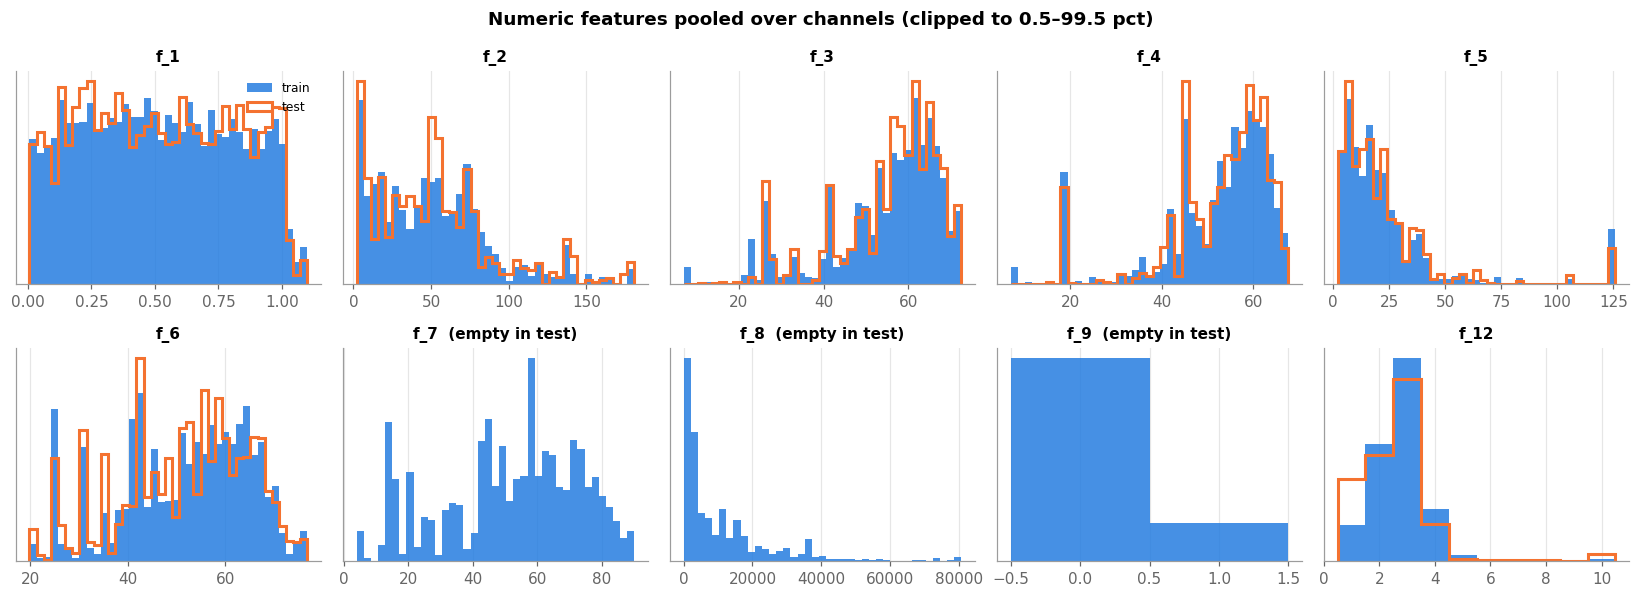

In [18]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5.5))
for ax, i in zip(axes.flat, num_i):
    tr = pd.concat([train[c] for c in fcols(train, i=i)]).dropna()
    te = pd.concat([test[c] for c in fcols(test, i=i)]).dropna()
    lo, hi = tr.quantile([0.005, 0.995])
    b = np.linspace(lo, hi, 40) if tr.nunique() > 40 else np.arange(lo - 0.5, hi + 1.5)
    ax.hist(tr.clip(lo, hi), bins=b, density=True, color=CH_COLOR[3], alpha=0.85, label="train")
    if len(te):
        ax.hist(te.clip(lo, hi), bins=b, density=True, histtype="step", linewidth=2, color=CH_COLOR[4], label="test")
    ax.set_title(f"f_{i}" + ("" if len(te) else "  (empty in test)"), fontsize=10)
    ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("Numeric features pooled over channels (clipped to 0.5–99.5 pct)", fontweight="bold")
plt.tight_layout(); plt.show()

Guesses about meaning (anonymised, so treat with care):
- `f_1` — programme progress (see §5).
- `f_2`, `f_5` — counts with a long tail (episodes / reruns?); `f_3`, `f_4`, `f_6` — scores in ~10–80 that
  correlate with each other; higher values go with *lower* ch3 share (see §11).
- `f_7` (score 4–94), `f_8` (big count, up to 126k), `f_9` (binary) — look like film-database metadata
  (rating, number of votes, flag); empty in test.
- `f_12` — small integer with a long tail (up to 37) → candidate for capping or treating as categorical.

Train and test distributions of the usable features match well — no obvious drift.

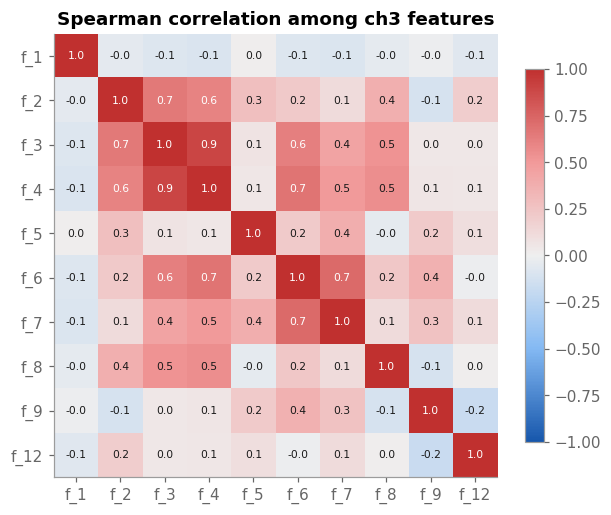

In [19]:
own = [f"ch3__f_{i}" for i in num_i]
cm = c3[own].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm.values, cmap=DIV, vmin=-1, vmax=1)
ax.set(xticks=range(len(own)), xticklabels=[c.split("__")[1] for c in own], yticks=range(len(own)),
       yticklabels=[c.split("__")[1] for c in own], title="Spearman correlation among ch3 features")
ax.grid(False)
for (r, c), v in np.ndenumerate(cm.values):
    ax.text(c, r, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "#191919")
fig.colorbar(im, ax=ax, shrink=0.8); plt.show()

## 10. Categorical features `f_10` (genre?) and `f_11` (country?) — train only

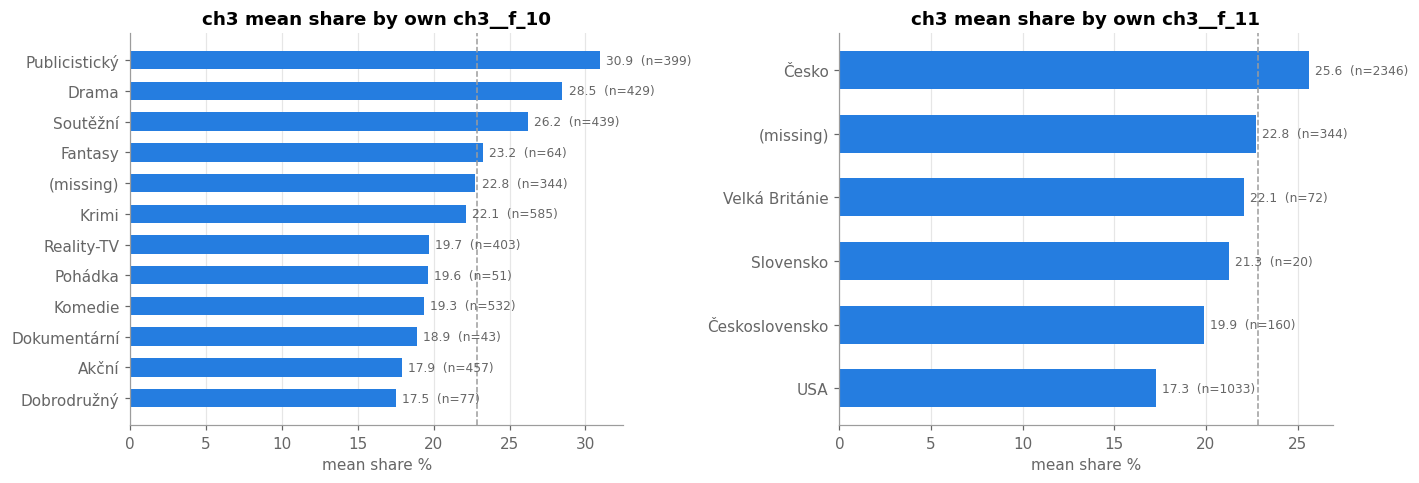

ch3: f_10 levels 27, f_11 levels 14, non-null in test: 0
ch4: f_10 levels 22, f_11 levels 18, non-null in test: 0
ch9: f_10 levels 0, f_11 levels 0, non-null in test: 0
ch54: f_10 levels 25, f_11 levels 36, non-null in test: 0


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, top in [(axes[0], "ch3__f_10", 12), (axes[1], "ch3__f_11", 6)]:
    g = c3.groupby(c3[col].fillna("(missing)"))[TARGET].agg(["mean", "size"]).sort_values("size", ascending=False).head(top)
    g = g.sort_values("mean")
    ax.barh(g.index, g["mean"], color=CH_COLOR[3], height=0.6)
    for y, (v, n) in enumerate(zip(g["mean"], g["size"])):
        ax.annotate(f"{v:.1f}  (n={n})", (v, y), xytext=(4, 0), textcoords="offset points", va="center",
                    fontsize=8, color=TEXT2)
    ax.axvline(c3[TARGET].mean(), color=GRAY, linestyle="--", linewidth=1)
    ax.set(title=f"ch3 mean share by own {col}", xlabel="mean share %"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
for ch in CHANNELS:
    print(f"ch{ch}: f_10 levels {train[f'ch{ch}__f_10'].nunique()}, f_11 levels {train[f'ch{ch}__f_11'].nunique()}, "
          f"non-null in test: {test[f'ch{ch}__f_10'].notna().sum()}")

Czech productions, drama and current-affairs (Publicistický) get far more share than US imports,
action and comedy. **But these columns are empty in test**, so the signal has to come from what
is available there (start time, suffix, `f_2`–`f_6`, `f_12`, 3mo mean).

## 11. What correlates with the ch3 target (only columns available in test)

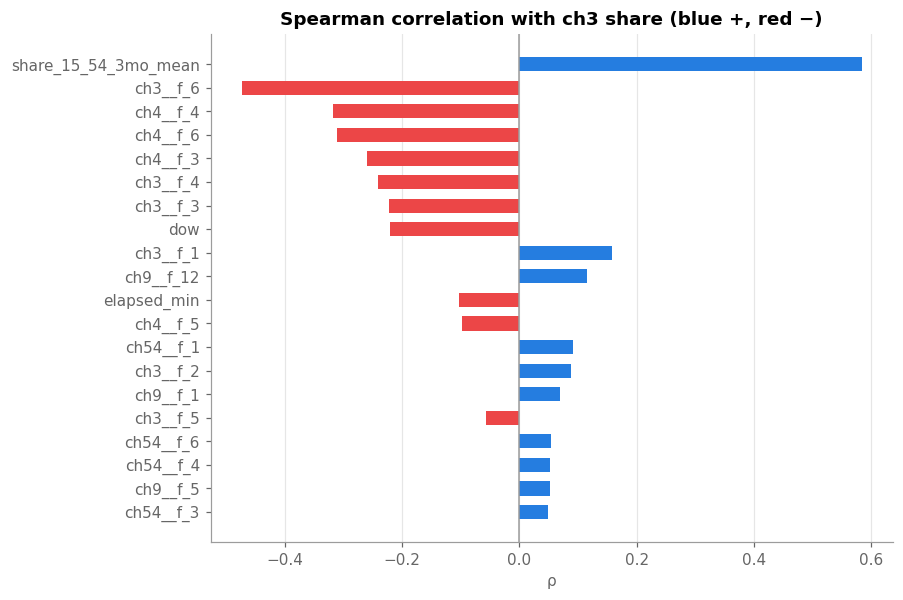

In [21]:
avail = [c for c in fcols(train) if train[c].dtype != object and test[c].notna().any()]
extra = [MO3, "elapsed_min", "hour", "dow", "minute_of_evening"]
cor = c3[avail + extra].corrwith(c3[TARGET], method="spearman").dropna()
cor = cor.reindex(cor.abs().sort_values(ascending=False).index).head(20)[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(cor.index, cor.values, color=[CH_COLOR[3] if v > 0 else "#ec4647" for v in cor.values], height=0.6)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set(title="Spearman correlation with ch3 share (blue +, red −)", xlabel="ρ"); ax.grid(axis="y", visible=False)
plt.show()

Linear/monotone correlations are modest — `hour` alone is weak because the profile is non-monotone
(peak at 19h). The strongest usable features are own `f_6` / `f_4` / `f_3` and the same features of
**competitor ch4**, all *negative*. Since own and competitor values push the same way, these are
probably not a simple "programme quality" score; they may partly encode time of day or programme type.
Check them conditional on hour before interpreting.

## 12. Competitor channels

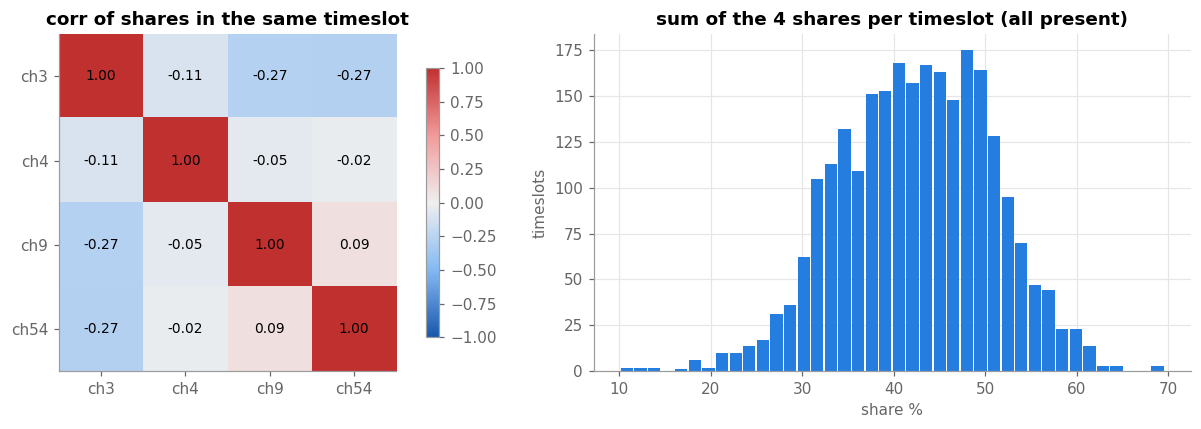

sum of 4 shares: {'count': 2553.0, 'mean': 42.5, 'std': 8.3, 'min': 10.1, '25%': 36.6, '50%': 42.8, '75%': 48.6, 'max': 69.5}


In [22]:
wide = train.pivot_table(index="timeslot_datetime_from", columns="channel_id", values=TARGET)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cm = wide.corr()
im = axes[0].imshow(cm.values, cmap=DIV, vmin=-1, vmax=1)
axes[0].set(xticks=range(4), xticklabels=[f"ch{c}" for c in cm.columns], yticks=range(4),
            yticklabels=[f"ch{c}" for c in cm.index], title="corr of shares in the same timeslot")
axes[0].grid(False)
for (r, c), v in np.ndenumerate(cm.values):
    axes[0].text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=axes[0], shrink=0.8)

tot = wide.dropna().sum(axis=1)
axes[1].hist(tot, bins=40, color=CH_COLOR[3], rwidth=0.9)
axes[1].set(title="sum of the 4 shares per timeslot (all present)", xlabel="share %", ylabel="timeslots")
plt.tight_layout(); plt.show()
print("sum of 4 shares:", tot.describe().round(1).to_dict())

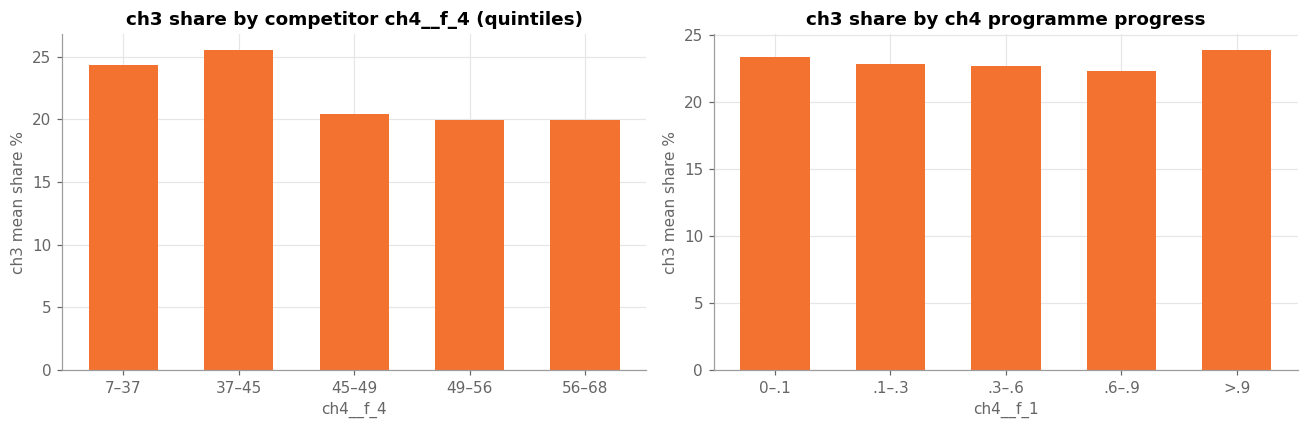

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
g = c3.groupby(pd.qcut(c3["ch4__f_4"], 5), observed=True)[TARGET].mean()
axes[0].bar(range(len(g)), g.values, color=CH_COLOR[4], width=0.6)
axes[0].set(xticks=range(len(g)), xticklabels=[f"{i.left:.0f}–{i.right:.0f}" for i in g.index],
            title="ch3 share by competitor ch4__f_4 (quintiles)", xlabel="ch4__f_4", ylabel="ch3 mean share %")
g = c3.groupby(pd.cut(c3["ch4__f_1"], [-0.01, 0.1, 0.3, 0.6, 0.9, 5]), observed=True)[TARGET].mean()
axes[1].bar(range(len(g)), g.values, color=CH_COLOR[4], width=0.6)
axes[1].set(xticks=range(len(g)), xticklabels=["0–.1", ".1–.3", ".3–.6", ".6–.9", ">.9"],
            title="ch3 share by ch4 programme progress", xlabel="ch4__f_1", ylabel="ch3 mean share %")
plt.tight_layout(); plt.show()

Shares of the four channels are only weakly negatively correlated (they compete with many other
channels; the four sum to ~42% on average). What ch4 airs (`f_4`) relates to ch3's
share much more than where in its programme ch4 is (`f_1`).

## 13. Takeaways for modelling

**Data issues**
1. Drop the ~48% exact duplicates in train (join fan-out); targets never conflict.
2. `f_7`–`f_11` (incl. genre/country) are empty in test → exclude; make the code robust to all-NaN and
   to dtype differences (`object` in train, `float` in test).
3. Sparse timeslot sampling, one missing day, not every channel present in every timeslot.

**Feature ideas**
- From `main_ident`: programme start time, minutes since start, suffix (`0010` ≈ 19:30 block).
- Calendar: hour / minute-of-evening, weekday vs weekend, holidays (Christmas, New Year, school breaks).
- `share_15_54_3mo_mean` as a level, combined with hour × weekday effects.
- Own `f_2`–`f_6`, `f_12` + missing indicators; competitors' (especially ch4) `f_3`–`f_6`.
- Do **not** target-encode `main_ident`: no test programme appears in train.

**Validation**
- Time-based split (e.g. train ≤ Aug 2023 → validate Sep–Oct 2023) and an extra fold on Nov 2022 –
  Jan 2023 to mimic the test season incl. Christmas.
- Report MAE per evening segment (early / prime / late) and worst week, as the jury does.
- Baseline to beat: hour × weekday mean, MAE ≈ 4.5.